In [45]:
#ctrl A (select all) then ctrl /
#to comment or uncomment the entire code cell

# Loading parsed files in

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

#load every saved batch back in
#EDIT PATH AS NEEDED
non_vpn1 = pd.read_pickle("/data/nonvpn1_files_AL2.pkl")
non_vpn2 = pd.read_pickle("/data/nonvpn2_files_AL2.pkl")
non_vpn3 = pd.read_pickle("/data/nonvpn3_files_AL2.pkl")
vpn = pd.read_pickle("/data/vpn_files_AL2.pkl")
tor = pd.read_pickle("/data/tor_files_AL2.pkl")

#combine into one dataframe
df_combined = pd.concat([non_vpn1, non_vpn2, non_vpn3, vpn, tor], ignore_index=True)

print(f"total combined flows: {len(df_combined)}")

#save the final combined dataset
#you can save it in 1 file if you wish
#df_combined.to_pickle("combined_flows.pkl")

print(f"shape: {df_combined.shape}")

#percentage distribution of network_type
print(df_combined["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_combined["category"].value_counts(normalize=True) * 100)

df_combined.head(3)

total combined flows: 188670
shape: (188670, 8)
network_type
non_vpn    89.884454
vpn         9.418031
tor         0.697514
Name: proportion, dtype: float64

category
audio            65.933641
file_transfer    21.262522
chat              6.302009
email             2.912493
streaming         1.423650
video             1.327715
p2p               0.817300
browsing          0.020671
Name: proportion, dtype: float64


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq
0,/kaggle/input/datasets/trayne/pcaps-data/NonVPN-PCAPs-01/email1a.pcap,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505, UDP)","[(1432572763.37583, 127, 1)]"
1,/kaggle/input/datasets/trayne/pcaps-data/NonVPN-PCAPs-01/email1a.pcap,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900, UDP)","[(1432572763.491782, 215, 1), (1432572763.491984, 215, 1), (1432572825.094788, 215, 1), (1432572825.094994, 215, 1), (1432572886.899927, 215, 1), (1432572886.900126, 215, 1), (1432572949.207177, 215, 1), (1432572949.207357, 215, 1), (1432573010.313515, 215, 1), (1432573010.313712, 215, 1), (1432573072.54013, 215, 1), (1432573072.540336, 215, 1), (1432573134.767248, 215, 1), (1432573134.76744, 215, 1), (1432573195.836074, 215, 1), (1432573195.836267, 215, 1), (1432573258.182779, 215, 1), (1432573258.182983, 215, 1), (1432573320.229188, 215, 1), (1432573320.229394, 215, 1)]"
2,/kaggle/input/datasets/trayne/pcaps-data/NonVPN-PCAPs-01/email1a.pcap,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.117, 54995, 255.255.255.255, 10505, UDP)","[(1432572763.515294, 131, 1)]"


In [47]:
first_row = df_combined.iloc[0]
for col in df_combined.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

filepath: /kaggle/input/datasets/trayne/pcaps-data/NonVPN-PCAPs-01/email1a.pcap
filename: email1a.pcap
stream_id: email1
part: a
network_type: non_vpn
category: email
flow_key: ('131.202.240.93', 57806, '255.255.255.255', 10505, 'UDP')
packet_seq: [(1432572763.37583, 127, 1)] ... (1 total packets)


# Cleaning

In [48]:
def get_flow_duration(packet_seq):
    if len(packet_seq) < 2: #need min 2 packets to find difference
        return 0 
    timestamps = [p[0] for p in packet_seq]
    return max(timestamps) - min(timestamps)

#duration of flow
df_combined["flow_duration"] = df_combined["packet_seq"].apply(get_flow_duration)

print("description")
print(df_combined["flow_duration"].describe())
print()
print("quantile")
print(df_combined["flow_duration"].quantile([0.5, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["flow_duration"].value_counts(bins=20).sort_index())

description
count    188670.000000
mean        252.848853
std         798.185257
min           0.000000
25%           0.144604
50%           0.412059
75%           0.421085
max        6413.501714
Name: flow_duration, dtype: float64

quantile
0.50       0.412059
0.75       0.421085
0.80       0.429883
0.85      58.915664
0.90     746.812158
0.95    2126.450915
0.99    4076.028234
1.00    6413.501714
Name: flow_duration, dtype: float64

bins
(-6.415, 320.675]       165223
(320.675, 641.35]         3538
(641.35, 962.025]         2894
(962.025, 1282.7]         2286
(1282.7, 1603.375]        2189
(1603.375, 1924.051]      2014
(1924.051, 2244.726]      1701
(2244.726, 2565.401]      1666
(2565.401, 2886.076]      1397
(2886.076, 3206.751]      1228
(3206.751, 3527.426]      1117
(3527.426, 3848.101]       956
(3848.101, 4168.776]       751
(4168.776, 4489.451]       570
(4489.451, 4810.126]       435
(4810.126, 5130.801]       350
(5130.801, 5451.476]       194
(5451.476, 5772.152]        7

In [49]:
#number of packets in each flow
df_combined["packet_count"] = df_combined["packet_seq"].apply(len)

print("description")
print(df_combined["packet_count"].describe())
print()
print("quantile")
print(df_combined["packet_count"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["packet_count"].value_counts(bins=20).sort_index())

description
count    1.886700e+05
mean     2.182734e+02
std      1.346167e+04
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.951457e+06
Name: packet_count, dtype: float64

quantile
0.50          2.0
0.75          2.0
0.90          4.0
0.95          6.0
0.99         71.0
1.00    2951457.0
Name: packet_count, dtype: float64

bins
(-2950.4570000000003, 147573.8]    188615
(147573.8, 295146.6]                   18
(295146.6, 442719.4]                   15
(442719.4, 590292.2]                    8
(590292.2, 737865.0]                    3
(737865.0, 885437.8]                    2
(885437.8, 1033010.6]                   2
(1033010.6, 1180583.4]                  0
(1180583.4, 1328156.2]                  0
(1328156.2, 1475729.0]                  5
(1475729.0, 1623301.8]                  0
(1623301.8, 1770874.6]                  0
(1770874.6, 1918447.4]                  0
(1918447.4, 2066020.2]                  0
(2066020.2, 2213593.0]        

In [50]:
#from above, most packets fall into first bin.
#find the number of flows that contain each packet, up to 20

print(df_combined["packet_count"].value_counts().sort_index().head(20))

packet_count
1      20923
2     133819
3        650
4      19807
5        234
6       4165
7        454
8        852
9        249
10       569
11       249
12       299
13       297
14       214
15       287
16       163
17       189
18       181
19       202
20       171
Name: count, dtype: int64


In [51]:
#distribution of network_type across each category
display(pd.crosstab(df_combined["category"], df_combined["network_type"]))

#same but as percentages within each category (row-wise)
(pd.crosstab(df_combined["category"], df_combined["network_type"], normalize="index") * 100).round(2)

network_type,non_vpn,tor,vpn
category,,,
audio,113085,26,11286
browsing,0,39,0
chat,7845,16,4029
email,5191,6,298
file_transfer,39090,6,1020
p2p,0,1065,477
streaming,1876,151,659
video,2498,7,0


network_type,non_vpn,tor,vpn
category,,,
audio,90.91,0.02,9.07
browsing,0.00,100.00,0.00
chat,65.98,0.13,33.89
email,94.47,0.11,5.42
file_transfer,97.44,0.01,2.54
p2p,0.00,69.07,30.93
streaming,69.84,5.62,24.53
video,99.72,0.28,0.00


In [52]:
#see how the duration is like for packet_count >=5
df_packet_filtered = df_combined[df_combined["packet_count"] >= 5]
print(df_packet_filtered["flow_duration"].describe())
print()
print(df_packet_filtered["flow_duration"].quantile([0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 1]))

count    13471.000000
mean      1111.686472
std       1526.169041
min          0.000846
25%          8.394011
50%        220.760416
75%       2037.051153
max       6413.501714
Name: flow_duration, dtype: float64

0.05       0.159927
0.10       0.485169
0.25       8.394011
0.50     220.760416
0.75    2037.051153
0.90    3634.037921
1.00    6413.501714
Name: flow_duration, dtype: float64


In [53]:
#the packet_count filter removed a lot of the flows with very low duration
#so dont need to filter noise from duration
MIN_PACKETS = 5 #spike at packet 2 and 4. so set min=5 to remove those noise
MIN_DURATION = 1.0 #set this to 1. duration < 1 has no meaningful temporal data

df_clean = df_combined[(df_combined["packet_count"] >= MIN_PACKETS) & (df_combined["flow_duration"] >= MIN_DURATION)].copy()
print(f"before: {len(df_combined)}, after: {len(df_clean)}")
print()
print(df_clean["flow_duration"].describe())
print()
print(df_clean["flow_duration"].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 1.0]))

before: 188670, after: 11885

count    11885.000000
mean      1260.000541
std       1566.265065
min          1.000637
25%         33.422062
50%        381.199485
75%       2343.469820
max       6413.501714
Name: flow_duration, dtype: float64

0.50     381.199485
0.75    2343.469820
0.90    3814.513671
0.95    4471.033657
0.99    5521.663819
1.00    6413.501714
Name: flow_duration, dtype: float64


In [54]:
#>90% data gone, keep everything instead
df_clean = df_combined.copy()
print(df_clean.shape)

(188670, 10)


In [55]:
#percentage distribution of network_type
print(df_clean["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_clean["category"].value_counts(normalize=True) * 100)

network_type
non_vpn    89.884454
vpn         9.418031
tor         0.697514
Name: proportion, dtype: float64

category
audio            65.933641
file_transfer    21.262522
chat              6.302009
email             2.912493
streaming         1.423650
video             1.327715
p2p               0.817300
browsing          0.020671
Name: proportion, dtype: float64


In [56]:
#duration by category and network
print("=== duration by category ===")
display(df_clean.groupby("category")["flow_duration"].describe())

print("\n=== duration by network_type ===")
display(df_clean.groupby("network_type")["flow_duration"].describe())

#results:
#CATEGORY
#audio dominates count, as expected
#all except browsing are on the shorter side
#all categories have much larger avg than median: few extreme outliers to pull them up

#NETWORK
#non_vpn longest, followed by tor and vpn

=== duration by category ===


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,124397.0,308.148002,902.010096,0.0,0.409034,0.412186,0.421009,6375.836560
browsing,39.0,856.975555,1279.147892,0.0,7.251899,270.381983,1055.243825,4902.175732
chat,11890.0,29.908396,139.406081,0.0,0.123447,0.132815,0.413073,1336.179729
email,5495.0,51.562513,347.505249,0.0,0.061097,0.411198,0.420667,5619.325462
file_transfer,40116.0,206.439670,632.100413,0.0,0.410587,0.413432,0.421846,5002.507509
p2p,1542.0,28.335634,282.823962,0.0,0.097483,0.324682,4.332572,6413.501714
streaming,2686.0,93.311724,290.712883,0.0,0.039827,10.634249,95.144367,6375.836560
video,2505.0,49.530756,210.050862,0.0,0.000372,0.000435,0.263753,3703.812379



=== duration by network_type ===


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,273.840255,828.744838,0.0,0.410272,0.412717,0.421256,5886.010418
tor,1316.0,130.854370,601.035816,0.0,0.000310,0.302471,7.207407,6413.501714
vpn,17769.0,61.544778,375.701018,0.0,0.000717,0.001935,0.133571,4116.135039


In [57]:
#bytes by category
def get_total_bytes(packet_seq):
    return sum(p[1] for p in packet_seq)

df_clean["total_bytes"] = df_clean["packet_seq"].apply(get_total_bytes)

print("bytes")
display(df_clean.groupby("category")["total_bytes"].describe())

#results
#all have large skews, probably from the outliers

bytes


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,124397.0,1.528053e+04,1.030392e+06,46.0,128.00,128.0,256.00,1.313403e+08
browsing,39.0,1.390910e+07,3.265400e+07,60.0,1069.00,13756.0,9857955.00,1.328807e+08
chat,11890.0,5.798393e+03,9.870564e+04,60.0,128.00,131.0,306.00,3.922199e+06
email,5495.0,6.223363e+04,2.267476e+06,60.0,128.00,128.0,131.00,1.096181e+08
file_transfer,40116.0,5.459081e+05,2.383998e+07,46.0,128.00,128.0,132.00,2.430622e+09
p2p,1542.0,3.507234e+06,6.289294e+07,54.0,217.75,507.0,1985.00,1.296150e+09
streaming,2686.0,1.332289e+06,1.879215e+07,54.0,334.00,516.0,3668.25,7.850586e+08
video,2505.0,2.249168e+06,3.524088e+07,54.0,302.00,334.0,581.00,1.191458e+09


In [58]:
#sanity check: 1 stream_id : 1 category
#return empty list if everything is correct

inconsistent = df_clean.groupby("stream_id")["category"].nunique()
print(inconsistent[inconsistent > 1])

Series([], Name: category, dtype: int64)


In [59]:
#min and max packet size across all flows in df_clean
all_sizes = pd.Series([p[1] for seq in df_clean["packet_seq"] for p in seq])
print(f"min packet size: {all_sizes.min()}")
print(f"max packet size: {all_sizes.max()}")

print("per network")
#min and max packet size per network_type
rows = []
for nt, g in df_clean.groupby("network_type"):
    s = pd.Series([p[1] for seq in g["packet_seq"] for p in seq])
    rows.append({"network_type": nt, "min": s.min(), "max": s.max()})
pd.DataFrame(rows)

min packet size: 30
max packet size: 65226
per network


,network_type,min,max
0,non_vpn,44,65226
1,tor,44,33516
2,vpn,30,1466


In [60]:
#find the duration at which each category reaches ~90% coverage
print("category")
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    p90 = cat_durations.quantile(0.90)
    print(f"{cat}: 90% coverage at {p90:.0f}s")

print("\nnetwork_type")

#find the duration at which each network_type reaches ~90% coverage
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    p90 = nt_durations.quantile(0.90)
    print(f"{nt}: 90% coverage at {p90:.0f}s")

print()

#coverage at 3000s, grouped by network_type
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    coverage = (nt_durations <= 600).mean() * 100
    print(f"{nt}: {coverage:.1f}% coverage at 300s")

category
email: 90% coverage at 2s
audio: 90% coverage at 1156s
video: 90% coverage at 63s
chat: 90% coverage at 0s
file_transfer: 90% coverage at 673s
streaming: 90% coverage at 241s
p2p: 90% coverage at 19s
browsing: 90% coverage at 2807s

network_type
non_vpn: 90% coverage at 927s
vpn: 90% coverage at 7s
tor: 90% coverage at 174s

non_vpn: 88.3% coverage at 300s
vpn: 97.6% coverage at 300s
tor: 94.7% coverage at 300s


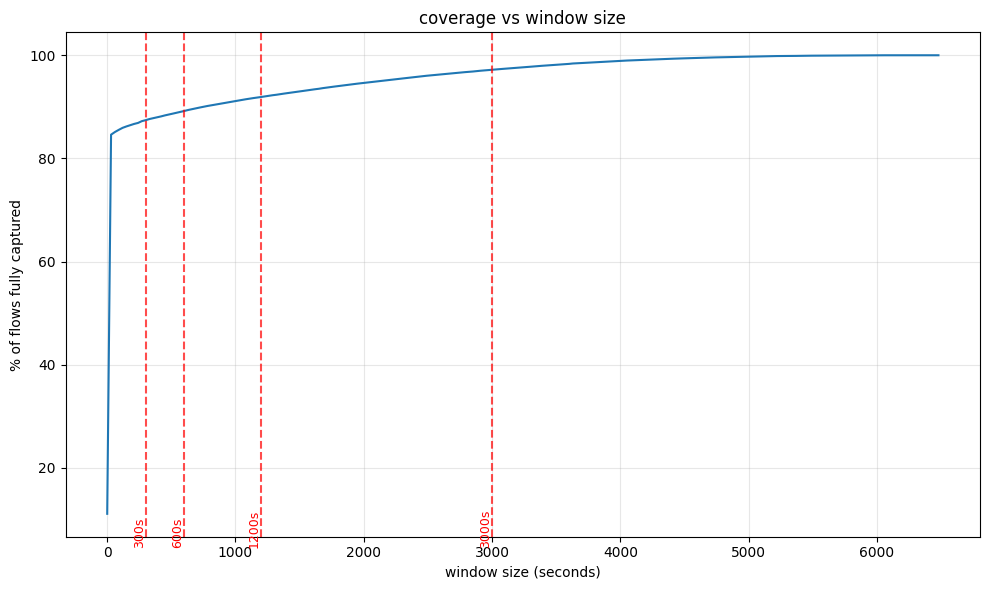

In [61]:
#compute coverage percentage for a range of window sizes
#see if there's any elbow to determine coverage for bucket
window_range = np.arange(0, 6500, 30)  #every 30 seconds, from 0 to max duration
coverage = [(df_clean["flow_duration"] <= w).mean() * 100 for w in window_range]

plt.figure(figsize=(10, 6))
plt.plot(window_range, coverage)
plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size")
plt.grid(True, alpha=0.3)

#mark candidate options for reference
plt.axvline(x=300, color="red", linestyle="--", alpha=0.7, label="candidate window (300s)")
plt.axvline(x=600, color="red", linestyle="--", alpha=0.7, label="candidate window (600s)")
plt.axvline(x=1200, color="red", linestyle="--", alpha=0.7, label="candidate window (1200s)")
plt.axvline(x=3000, color="red", linestyle="--", alpha=0.7, label="candidate window (3000s)")
plt.text(300, 5, "300s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(600, 5, "600s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(1200, 5, "1200s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(3000, 5, "3000s", rotation=90, fontsize=9, color="red", ha="right")

plt.tight_layout()
#plt.savefig("coverage_vs_window.png", dpi=150, bbox_inches="tight")
plt.show()

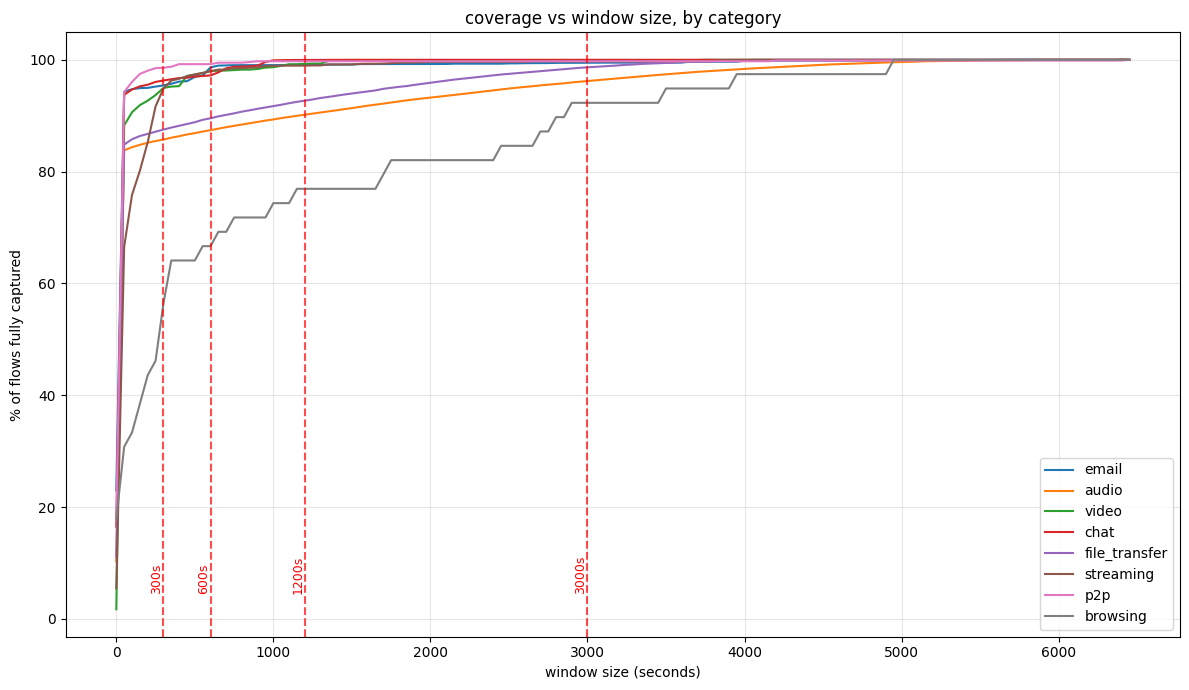

In [62]:
#coverage curve, but broken down by category
window_range = np.arange(0, 6500, 50)

plt.figure(figsize=(12, 7))
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    coverage = [(cat_durations <= w).mean() * 100 for w in window_range]
    plt.plot(window_range, coverage, label=cat)

plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size, by category")
plt.legend()
plt.grid(True, alpha=0.3)

#add the 1200s and 3000s reference line
plt.axvline(x=300, color="red", linestyle="--", alpha=0.7, label="candidate window (300s)")
plt.axvline(x=600, color="red", linestyle="--", alpha=0.7, label="candidate window (600s)")
plt.axvline(x=1200, color="red", linestyle="--", alpha=0.7, label="candidate window (1200s)")
plt.axvline(x=3000, color="red", linestyle="--", alpha=0.7, label="candidate window (3000s)")
plt.text(300, 5, "300s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(600, 5, "600s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(1200, 5, "1200s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(3000, 5, "3000s", rotation=90, fontsize=9, color="red", ha="right")

plt.tight_layout()
#plt.savefig("coverage_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

#just choose 3000s as coverage for bucketing

# Bucketing

In [63]:
# #ADJUST THE BUCKETS
# #300s coverage: 30 * 10
# BUCKET_SIZE_SECONDS = 30
# NUM_BUCKETS = 10 

# #bytes sent and received per bucket
# def bucket_bytes_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
#     if len(packet_seq) == 0:
#         return np.zeros(num_buckets * 2)

#     flow_start = packet_seq[0][0]
#     bytes_out = np.zeros(num_buckets)
#     bytes_in = np.zeros(num_buckets)

#     for timestamp, size, direction in packet_seq:
#         elapsed = timestamp - flow_start
#         bucket_index = int(elapsed // bucket_size)
#         if bucket_index < num_buckets:
#             if direction > 0:
#                 bytes_out[bucket_index] += size
#             else:
#                 bytes_in[bucket_index] += size

#     return np.concatenate([bytes_out, bytes_in])

# #packets sent and received per bucket
# def bucket_packets_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
#     if len(packet_seq) == 0:
#         return np.zeros(num_buckets * 2)

#     flow_start = packet_seq[0][0]
#     packets_out = np.zeros(num_buckets)
#     packets_in = np.zeros(num_buckets)

#     for timestamp, size, direction in packet_seq:
#         elapsed = timestamp - flow_start
#         bucket_index = int(elapsed // bucket_size)
#         if bucket_index < num_buckets:
#             if direction > 0:
#                 packets_out[bucket_index] += 1
#             else:
#                 packets_in[bucket_index] += 1

#     return np.concatenate([packets_out, packets_in])

# #mean and std of time between consecutive packets per bucket
# def bucket_timing_stats(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
#     if len(packet_seq) < 2:
#         return np.zeros(num_buckets * 2)  #mean and std per bucket

#     flow_start = packet_seq[0][0]
#     bucket_gaps = [[] for _ in range(num_buckets)]

#     timestamps = [p[0] for p in packet_seq]
#     for i in range(1, len(timestamps)):
#         gap = timestamps[i] - timestamps[i-1]
#         elapsed = timestamps[i] - flow_start
#         bucket_index = int(elapsed // bucket_size)
#         if bucket_index < num_buckets:
#             bucket_gaps[bucket_index].append(gap)

#     mean_gaps = np.array([np.mean(g) if g else 0 for g in bucket_gaps])
#     std_gaps = np.array([np.std(g) if g else 0 for g in bucket_gaps])

#     return np.concatenate([mean_gaps, std_gaps])

# #mean and std of bytes of each packet per bucket
# def bucket_size_stats(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
#     if len(packet_seq) == 0:
#         return np.zeros(num_buckets * 2)  #mean and std per bucket

#     flow_start = packet_seq[0][0]
#     bucket_sizes = [[] for _ in range(num_buckets)]

#     for timestamp, size, direction in packet_seq:
#         elapsed = timestamp - flow_start
#         bucket_index = int(elapsed // bucket_size)
#         if bucket_index < num_buckets:
#             bucket_sizes[bucket_index].append(size)

#     mean_sizes = np.array([np.mean(s) if s else 0 for s in bucket_sizes])
#     std_sizes = np.array([np.std(s) if s else 0 for s in bucket_sizes])

#     return np.concatenate([mean_sizes, std_sizes])

In [64]:
# #8 * 10 more columns here 

# #apply and expand into columns: bytes_out_0...9, bytes_in_0...9
# bytes_result = df_clean["packet_seq"].apply(bucket_bytes_by_direction)
# bytes_cols = [f"bytes_out_{i}" for i in range(NUM_BUCKETS)] + [f"bytes_in_{i}" for i in range(NUM_BUCKETS)]
# df_bytes = pd.DataFrame(bytes_result.tolist(), columns=bytes_cols, index=df_clean.index)

# #apply and expand into columns: packets_out_0...9, packets_in_0...9
# packets_result = df_clean["packet_seq"].apply(bucket_packets_by_direction)
# packets_cols = [f"packets_out_{i}" for i in range(NUM_BUCKETS)] + [f"packets_in_{i}" for i in range(NUM_BUCKETS)]
# df_packets = pd.DataFrame(packets_result.tolist(), columns=packets_cols, index=df_clean.index)

# #timing stats: mean and std of inter-arrival time, per bucket
# timing_result = df_clean["packet_seq"].apply(bucket_timing_stats)
# timing_cols = [f"gap_mean_{i}" for i in range(NUM_BUCKETS)] + [f"gap_std_{i}" for i in range(NUM_BUCKETS)]
# df_timing = pd.DataFrame(timing_result.tolist(), columns=timing_cols, index=df_clean.index)

# #size stats: mean and std of packet size, per bucket
# size_result = df_clean["packet_seq"].apply(bucket_size_stats)
# size_cols = [f"size_mean_{i}" for i in range(NUM_BUCKETS)] + [f"size_std_{i}" for i in range(NUM_BUCKETS)]
# df_size = pd.DataFrame(size_result.tolist(), columns=size_cols, index=df_clean.index)

In [65]:
# print(f"before shape: {df_clean.shape}")

# #combine with original columns
# df_clean_features = pd.concat([df_clean, df_bytes, df_packets, df_timing, df_size], axis=1)
# print(f"after shape: {df_clean_features.shape}")
# df_clean_features.head(3)

# Log-spaced bucketing

In [66]:
# ---------------------------------------------------------------------------
# LOG-SPACED BUCKETING (replaces the uniform bucketing cells)
# Same feature families and column names as before, so the EDA cells still work:
#   bytes_out_i / bytes_in_i, packets_out_i / packets_in_i,
#   gap_mean_i / gap_std_i,  size_mean_i / size_std_i
# ---------------------------------------------------------------------------

# --- CONFIG ---------------------------------------------------------------
T_MIN       = 0.01     # end of the first bucket in seconds (bucket 0 = 0 to T_MIN)
T_MAX       = 5    # Z: end of the last bucket in seconds; later packets are dropped
NUM_BUCKETS = 28      # X: number of buckets (more buckets = finer, smaller ratio between edges)

# edges: [0, T_MIN, ..., T_MAX]  ->  NUM_BUCKETS buckets
BUCKET_EDGES = np.concatenate([[0.0], np.geomspace(T_MIN, T_MAX, NUM_BUCKETS)])
assert len(BUCKET_EDGES) - 1 == NUM_BUCKETS

bucket_info = pd.DataFrame({
    "bucket": np.arange(NUM_BUCKETS),
    "start_s": BUCKET_EDGES[:-1],
    "end_s": BUCKET_EDGES[1:],
})
bucket_info["width_s"] = bucket_info["end_s"] - bucket_info["start_s"]
print(f"ratio between consecutive edges: {BUCKET_EDGES[2] / BUCKET_EDGES[1]:.3f}")
display(bucket_info.round(3))


# --- FEATURE FUNCTIONS ------------------------------------------------------
def _count(idx, mask):
    return np.bincount(idx[mask], minlength=NUM_BUCKETS).astype(float)

def _sum(idx, mask, vals):
    return np.bincount(idx[mask], weights=vals[mask], minlength=NUM_BUCKETS)

def _mean_std(idx, mask, vals):
    """per-bucket mean and (population) std, 0 where the bucket is empty"""
    n  = _count(idx, mask)
    s  = _sum(idx, mask, vals)
    s2 = _sum(idx, mask, vals ** 2)
    mean = np.divide(s, n, out=np.zeros(NUM_BUCKETS), where=n > 0)
    var = np.divide(s2, n, out=np.zeros(NUM_BUCKETS), where=n > 0) - mean ** 2
    return mean, np.sqrt(np.maximum(var, 0))

N_FEATS = 8 * NUM_BUCKETS

def bucket_features_log(packet_seq):
    """
    one flow -> concatenated array in this order (each block has NUM_BUCKETS values):
      bytes_out, bytes_in, packets_out, packets_in,
      gap_mean, gap_std, size_mean, size_std
    """
    if len(packet_seq) == 0:
        return np.zeros(N_FEATS)

    arr = np.asarray(packet_seq, dtype=float)             # columns: timestamp, size, direction
    arr = arr[np.argsort(arr[:, 0], kind="stable")]       # make sure packets are time-ordered
    t, size, direction = arr[:, 0] - arr[0, 0], arr[:, 1], arr[:, 2]

    # bucket index of every packet; packets at/after T_MAX get index == NUM_BUCKETS and are dropped
    idx = np.searchsorted(BUCKET_EDGES, t, side="right") - 1
    keep = idx < NUM_BUCKETS
    is_out = keep & (direction > 0)
    is_in  = keep & (direction <= 0)

    bytes_out, bytes_in = _sum(idx, is_out, size), _sum(idx, is_in, size)
    pkts_out,  pkts_in  = _count(idx, is_out),     _count(idx, is_in)

    size_mean, size_std = _mean_std(idx, keep, size)

    # inter-arrival gap belongs to the bucket of the later packet (same as the old code)
    if len(t) >= 2:
        gaps = np.diff(t)
        gap_mean, gap_std = _mean_std(idx[1:], keep[1:], gaps)
    else:
        gap_mean = gap_std = np.zeros(NUM_BUCKETS)

    return np.concatenate([bytes_out, bytes_in, pkts_out, pkts_in,
                           gap_mean, gap_std, size_mean, size_std])


# --- BUILD THE FEATURE TABLE ------------------------------------------------
# keep the old uniform-bucket table around for comparison, if it exists
if "df_clean_features" in globals():
    df_clean_features_uniform = df_clean_features

feat = np.vstack([bucket_features_log(s) for s in df_clean["packet_seq"]])
B = NUM_BUCKETS
_names = lambda p: [f"{p}_{i}" for i in range(B)]

bytes_cols   = _names("bytes_out")   + _names("bytes_in")
packets_cols = _names("packets_out") + _names("packets_in")
timing_cols  = _names("gap_mean")    + _names("gap_std")
size_cols    = _names("size_mean")   + _names("size_std")

df_bytes   = pd.DataFrame(feat[:, 0 * B:2 * B], columns=bytes_cols,   index=df_clean.index)
df_packets = pd.DataFrame(feat[:, 2 * B:4 * B], columns=packets_cols, index=df_clean.index)
df_timing  = pd.DataFrame(feat[:, 4 * B:6 * B], columns=timing_cols,  index=df_clean.index)
df_size    = pd.DataFrame(feat[:, 6 * B:8 * B], columns=size_cols,    index=df_clean.index)

print(f"before shape: {df_clean.shape}")
df_clean_features = pd.concat([df_clean, df_bytes, df_packets, df_timing, df_size], axis=1)
print(f"after shape: {df_clean_features.shape}")

ratio between consecutive edges: 1.259


,bucket,start_s,end_s,width_s
0,0,0.000,0.010,0.010
1,1,0.010,0.013,0.003
2,2,0.013,0.016,0.003
3,3,0.016,0.020,0.004
4,4,0.020,0.025,0.005
5,5,0.025,0.032,0.006
6,6,0.032,0.040,0.008
7,7,0.040,0.050,0.010
8,8,0.050,0.063,0.013
9,9,0.063,0.079,0.016


before shape: (188670, 11)
after shape: (188670, 235)


# EDA

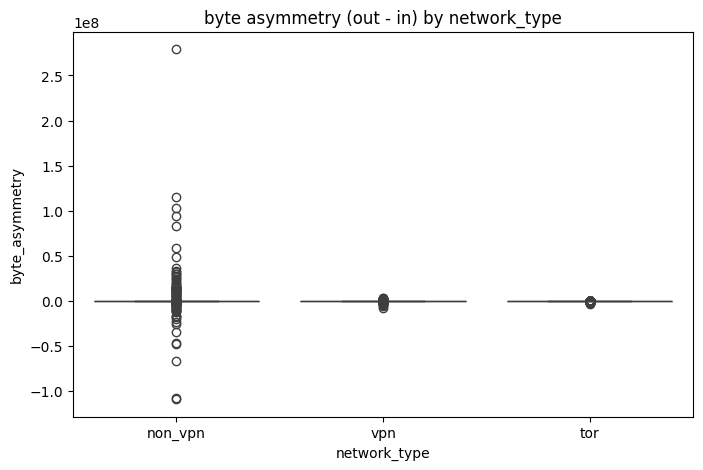

In [67]:
#asymmetry between bytes out and bytes in, across network_type
bytes_out_cols = [c for c in df_clean_features.columns if c.startswith("bytes_out_")]
bytes_in_cols = [c for c in df_clean_features.columns if c.startswith("bytes_in_")]

df_clean_features["total_bytes_out"] = df_clean_features[bytes_out_cols].sum(axis=1)
df_clean_features["total_bytes_in"] = df_clean_features[bytes_in_cols].sum(axis=1)
df_clean_features["byte_asymmetry"] = df_clean_features["total_bytes_out"] - df_clean_features["total_bytes_in"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry")
plt.title("byte asymmetry (out - in) by network_type")
plt.show()

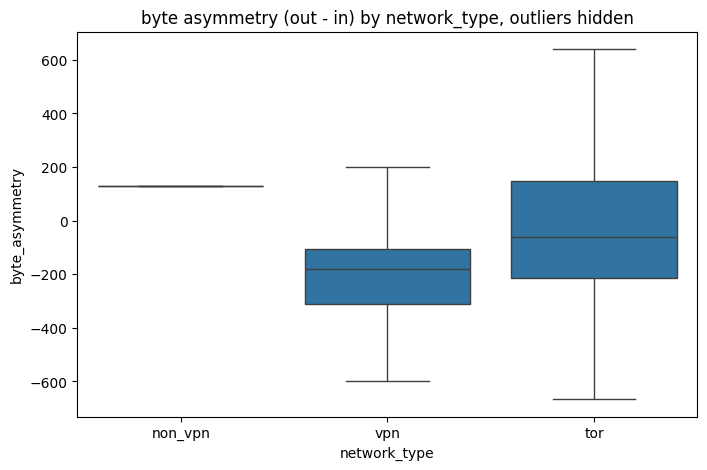

In [68]:
#boxplot with outliers hidden, so the box itself is visible
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry", showfliers=False)
plt.title("byte asymmetry (out - in) by network_type, outliers hidden")
plt.show()

In [69]:
#precise stats, including iqr, for each network_type
df_clean_features.groupby("network_type")["byte_asymmetry"].describe()

#conclusion: splitting into bytes in and out does seem to help distinguish the network

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,4129.780405,1.012287e+06,-108973710.0,128.0,128.0,128.0,279266137.0
tor,1316.0,-84934.734043,2.950009e+05,-3240204.0,-213.0,-61.0,148.0,97973.0
vpn,17769.0,-11070.852271,1.495067e+05,-7946294.0,-312.0,-182.0,-107.0,2760003.0


count    188670.000000
mean         96.109467
std           3.597156
min           0.000000
25%          96.428571
50%          96.428571
75%          96.428571
max          98.214286
Name: zero_bucket_pct, dtype: float64


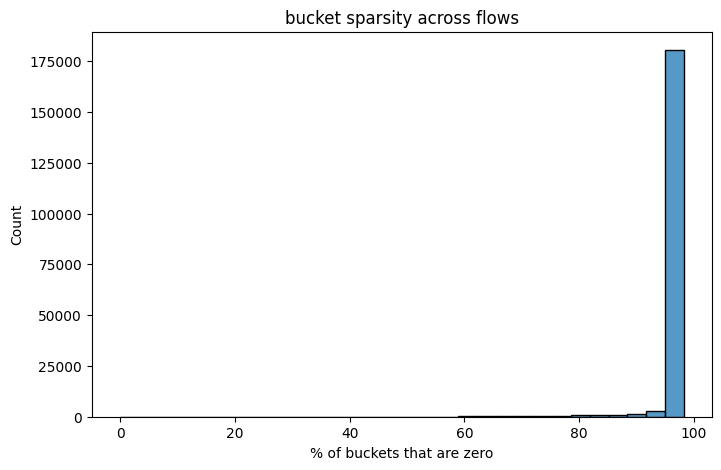

In [70]:
#sparsity check: % of buckets that are zero, per flow
feature_cols = bytes_out_cols + bytes_in_cols
zero_pct_per_flow = (df_clean_features[feature_cols] == 0).sum(axis=1) / len(feature_cols) * 100

df_clean_features["zero_bucket_pct"] = zero_pct_per_flow
print(df_clean_features["zero_bucket_pct"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df_clean_features["zero_bucket_pct"], bins=30)
plt.xlabel("% of buckets that are zero")
plt.title("bucket sparsity across flows")
plt.show()

In [71]:
#does sparsity differ meaningfully by network_type
df_clean_features.groupby("network_type")["zero_bucket_pct"].describe()

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,96.308562,2.873097,0.000000,96.428571,96.428571,96.428571,98.214286
tor,1316.0,90.752551,12.272315,21.428571,89.285714,96.428571,96.428571,98.214286
vpn,17769.0,94.606076,6.534663,19.642857,96.428571,96.428571,96.428571,98.214286


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,0.012102,0.009743,0.0,0.014625,0.014700,0.014967,0.178566
tor,1316.0,0.008806,0.017853,0.0,0.000009,0.003618,0.008382,0.161184
vpn,17769.0,0.004892,0.012571,0.0,0.000026,0.000062,0.004651,0.178551


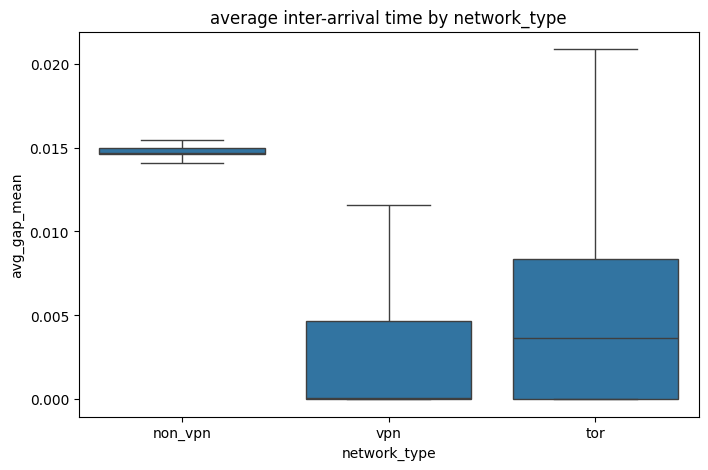

In [72]:
#summarise mean inter-arrival time (averaged across buckets) per network_type
gap_mean_cols = [c for c in df_clean_features.columns if c.startswith("gap_mean_")]
df_clean_features["avg_gap_mean"] = df_clean_features[gap_mean_cols].mean(axis=1)
display(df_clean_features.groupby("network_type")["avg_gap_mean"].describe())

#visualise it
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="avg_gap_mean", showfliers=False)
plt.title("average inter-arrival time by network_type")
plt.show()

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,1.993232,52.604710,0.0,0.0,0.000000,0.000000,6384.033225
tor,1316.0,28.096117,71.546652,0.0,0.0,0.000000,7.795059,810.249256
vpn,17769.0,7.718060,25.103025,0.0,0.0,3.142857,5.571429,340.991176


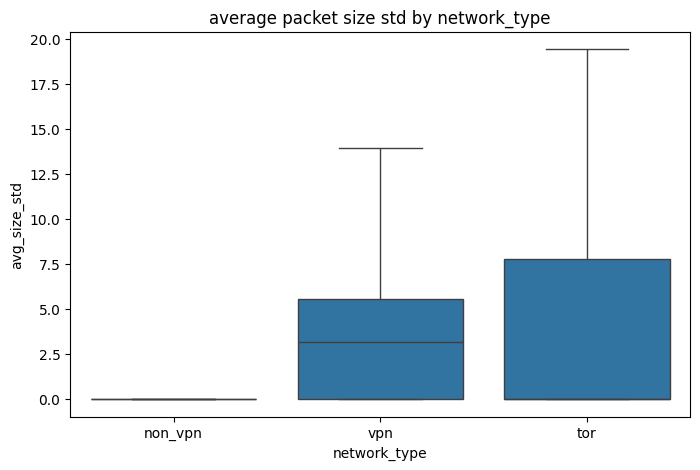

In [73]:
gap_std_cols = [c for c in df_clean_features.columns if c.startswith("size_std_")]
df_clean_features["avg_size_std"] = df_clean_features[gap_std_cols].mean(axis=1)
display(df_clean_features.groupby("network_type")["avg_size_std"].describe())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="avg_size_std", showfliers=False)
plt.title("average packet size std by network_type")
plt.show()

# Splitting into train/validate/test set

In [74]:
# #dropping category cause some network types are missing within some categories
# #e.g. browsing only has Tor
# X = df_clean_features.drop(columns=['filepath', 'filename', 'stream_id', 'part', 'category',
#                                     'flow_key', 'packet_seq', 'flow_duration', 'packet_count',
#                                     'total_bytes', 'network_type', 'total_bytes_out', 'total_bytes_in',
#                                     'byte_asymmetry', 'zero_bucket_pct', 'avg_gap_mean',
#                                     'avg_size_std'])

# y = df_clean_features["network_type"]

# print(X.shape)
# print(X.columns)

In [75]:
# from sklearn.model_selection import GroupShuffleSplit

# #use stream_id for grouping the split
# groups = df_clean_features["stream_id"]

# #split 1: 70% train, 30% temp, grouped by stream_id
# gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=4266)
# train_idx, temp_idx = next(gss.split(X, y, groups=groups))

# X_train, X_temp = X.iloc[train_idx], X.iloc[temp_idx]
# y_train, y_temp = y.iloc[train_idx], y.iloc[temp_idx]
# groups_temp = groups.iloc[temp_idx]

# #split 2: temp into 50% validation, 50% test, grouped by stream_id
# gss_temp = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=4266)
# val_idx, test_idx = next(gss_temp.split(X_temp, y_temp, groups=groups_temp))

# X_val, X_test = X_temp.iloc[val_idx], X_temp.iloc[test_idx]
# y_val, y_test = y_temp.iloc[val_idx], y_temp.iloc[test_idx]

# #for verification
# groups_train = groups.iloc[train_idx]
# groups_val = groups_temp.iloc[val_idx]
# groups_test = groups_temp.iloc[test_idx]

# print("Train rows:", len(X_train))
# print("Validation rows:", len(X_val))
# print("Test rows:", len(X_test))

# print("Train groups:", groups_train.nunique())
# print("Validation groups:", groups_val.nunique())
# print("Test groups:", groups_test.nunique())

# print("Train-Val overlap:",
#       len(set(groups_train) & set(groups_val)))

# print("Train-Test overlap:",
#       len(set(groups_train) & set(groups_test)))

# print("Val-Test overlap:",
#       len(set(groups_val) & set(groups_test)))

In [76]:
# trying a third way: capping flows per stream
stream_info = df_clean_features.groupby(["network_type", "stream_id"]).size()
for cap in [100, 200, 500, 1000]:
    print(cap, stream_info.clip(upper=cap).groupby(level=0).sum().to_dict())

#cap flows per stream here
MAX_FLOWS_PER_STREAM = 200

# preview class sizes under different caps (useful for the group)
stream_info = df_clean_features.groupby(["network_type", "stream_id"]).size()
print("Flows per class under different caps:")
for cap in [100, 200, 500, 1000, None]:
    counts = stream_info if cap is None else stream_info.clip(upper=cap)
    print(f"  cap={cap}:", counts.groupby(level=0).sum().to_dict())

# shuffle, then keep at most N flows per stream (= random sample per stream)
df_capped = (df_clean_features
             .sample(frac=1, random_state=4266)
             .groupby("stream_id")
             .head(MAX_FLOWS_PER_STREAM)
             .reset_index(drop=True))

print(f"\nUsing cap = {MAX_FLOWS_PER_STREAM}")
print(df_capped["network_type"].value_counts())
tor_streams = df_capped[df_capped["network_type"] == "tor"]["stream_id"].value_counts()
print("Biggest Tor stream's share now:", round(tor_streams.iloc[0] / tor_streams.sum() * 100, 1), "%")


# features + stratified group split here first
from sklearn.model_selection import StratifiedGroupKFold

feature_cols = bytes_cols + packets_cols + timing_cols + size_cols
X = df_capped[feature_cols]
y = df_capped["network_type"]
groups = df_capped["stream_id"]

def make_split(seed):
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    tv, te = next(sgkf.split(X, y, groups))
    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    tr, va = next(sgkf2.split(X.iloc[tv], y.iloc[tv], groups.iloc[tv]))
    return tv[tr], tv[va], te

def split_error(tr, va, te):
    """Worst-case gap between any class's split % and the 72/14/14 target."""
    pct = pd.DataFrame({"train": y.iloc[tr].value_counts(),
                        "val": y.iloc[va].value_counts(),
                        "test": y.iloc[te].value_counts()}).fillna(0)
    pct = pct.div(pct.sum(axis=1), axis=0)
    target = pd.Series({"train": 0.72, "val": 0.14, "test": 0.14})
    return (pct - target).abs().max().max()

errors = {s: split_error(*make_split(s)) for s in range(100)}
best_seed = min(errors, key=errors.get)
print(f"Best seed: {best_seed} (worst-case gap: {errors[best_seed]:.1%})")

train_idx, val_idx, test_idx = make_split(best_seed)
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]

# check: counts and % per split
dist = pd.DataFrame({"train": y_train.value_counts(),
                     "val": y_val.value_counts(),
                     "test": y_test.value_counts()}).fillna(0).astype(int)
print(dist, "\n")
print((dist.div(dist.sum(axis=1), axis=0) * 100).round(1), "\n")

# check: no stream in two splits (should be 0 0 0)
g_tr, g_va, g_te = set(groups.iloc[train_idx]), set(groups.iloc[val_idx]), set(groups.iloc[test_idx])
print("Overlaps:", len(g_tr & g_va), len(g_tr & g_te), len(g_va & g_te))

100 {'non_vpn': 6112, 'tor': 371, 'vpn': 1808}
200 {'non_vpn': 9687, 'tor': 471, 'vpn': 3118}
500 {'non_vpn': 15300, 'tor': 771, 'vpn': 6118}
1000 {'non_vpn': 20790, 'tor': 1271, 'vpn': 9404}
Flows per class under different caps:
  cap=100: {'non_vpn': 6112, 'tor': 371, 'vpn': 1808}
  cap=200: {'non_vpn': 9687, 'tor': 471, 'vpn': 3118}
  cap=500: {'non_vpn': 15300, 'tor': 771, 'vpn': 6118}
  cap=1000: {'non_vpn': 20790, 'tor': 1271, 'vpn': 9404}
  cap=None: {'non_vpn': 169585, 'tor': 1316, 'vpn': 17769}

Using cap = 200
network_type
non_vpn    9687
vpn        3118
tor         471
Name: count, dtype: int64
Biggest Tor stream's share now: 42.5 %
Best seed: 2 (worst-case gap: 3.4%)
              train   val  test
network_type                   
non_vpn        6939  1196  1552
vpn            2235   342   541
tor             331    61    79 

              train   val  test
network_type                   
non_vpn        71.6  12.3  16.0
vpn            71.7  11.0  17.4
tor            70.3  1

# Data Augmentation

In [77]:
#augmentation functions
rng = np.random.default_rng(4266)
WINDOW = T_MAX   # features now only see the first T_MAX seconds

#randomly shifts a later part of the flow to be the "first" WINDOW seconds in data
def aug_window_shift(seq, window=WINDOW):
    t0, t_end = seq[0][0], seq[-1][0]
    if t_end - t0 <= window:
        return None
    start = rng.uniform(t0, t_end - window)
    sub = [p for p in seq if p[0] >= start]
    return sub if len(sub) >= 2 else None

#takes the gaps between consecutive packets and scales them all by one random factor between 0.9 and 1.1
#also adds a little per-gap noise (about 5%, clipped to 0.5 to 1.5), then rebuilds the
#timestamps from the cumulative sum
def aug_time_jitter(seq, scale_range=(0.9, 1.1), noise=0.05):
    times = np.array([p[0] for p in seq])
    gaps = np.diff(times, prepend=times[0])
    factor = rng.uniform(*scale_range)
    gaps = gaps * factor * rng.normal(1, noise, len(gaps)).clip(0.5, 1.5)
    new_times = times[0] + np.cumsum(gaps)
    return [(t, s, d) for t, (_, s, d) in zip(new_times, seq)]
    
#adds a random integer from -8 to +8 to each packet size, clipped to between 54 and 1514 bytes
#skipped for tor
#maybe change min and max to the ones represented in the data
def aug_size_jitter(seq, max_delta=8, min_size=54, max_size=1514):
    return [(t, int(np.clip(s + rng.integers(-max_delta, max_delta + 1), min_size, max_size)), d)
            for t, s, d in seq]

#3% chance of the packet going missing
def aug_packet_drop(seq, p=0.03):
    if len(seq) < 5:
        return list(seq)
    keep = rng.random(len(seq)) > p
    keep[0] = True
    return [pkt for pkt, k in zip(seq, keep) if k]

#chains the above functions tgt
def augment_flow(seq, is_tor=False):
    s = list(seq)
    if rng.random() < 0.5:
        shifted = aug_window_shift(s)
        if shifted:
            s = shifted
    s = aug_time_jitter(s)
    if not is_tor:            # protect Tor's fixed 512-byte cell sizes
        s = aug_size_jitter(s)
    s = aug_packet_drop(s)
    return s

#rebuilds the features
def flow_features(seq):
    return bucket_features_log(seq)

In [78]:
AUGMENT_CLASSES = {"tor"}   # VPN handled by class weights
TARGET_RATIO = 0.5          # grow to at most 50% of the biggest class...
MAX_MULTIPLIER = 5          # ...and at most 5x original size
MIN_PACKETS = 5

train_df = df_capped.iloc[train_idx]
counts = train_df["network_type"].value_counts()
print("Before:\n", counts, "\n")

aug_rows, aug_labels = [], []
for cls in AUGMENT_CLASSES:
    if cls not in counts:
        continue
    n = counts[cls]
    n_needed = min(int(counts.max() * TARGET_RATIO), n * MAX_MULTIPLIER) - n
    pool = train_df[(train_df["network_type"] == cls) & (train_df["packet_count"] >= MIN_PACKETS)]
    if n_needed <= 0 or len(pool) == 0:
        continue

    print(f"{cls}: {pool['stream_id'].nunique()} streams in pool, "
          f"{(pool['flow_duration'] > WINDOW).mean():.1%} of flows longer than {WINDOW}s")

    # every stream gets an equal chance, so one big stream can't dominate
    stream_sizes = pool["stream_id"].map(pool["stream_id"].value_counts())
    sampled = pool.sample(n_needed, replace=True, weights=1 / stream_sizes, random_state=4266)

    is_tor = "tor" in str(cls).lower()
    for seq in sampled["packet_seq"]:
        aug_rows.append(flow_features(augment_flow(seq, is_tor=is_tor)))
        aug_labels.append(cls)

X_aug = pd.DataFrame(aug_rows, columns=feature_cols)
y_aug = pd.Series(aug_labels, name="network_type")

X_train_aug = pd.concat([X_train.reset_index(drop=True), X_aug], ignore_index=True)
y_train_aug = pd.concat([y_train.reset_index(drop=True), y_aug], ignore_index=True)
print("\nAfter:\n", y_train_aug.value_counts())

Before:
 network_type
non_vpn    6939
vpn        2235
tor         331
Name: count, dtype: int64 

tor: 36 streams in pool, 66.0% of flows longer than 5s

After:
 network_type
non_vpn    6939
vpn        2235
tor        1655
Name: count, dtype: int64


# BASELINE

In [79]:
# =====================================================================
# BASELINE: majority class + logistic regression, on the FINAL pipeline
# Prints every number needed for Section IV-A
# =====================================================================
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             classification_report, confusion_matrix)

labels = ["non_vpn", "vpn", "tor"]

def prep(Xtr, Xev):
    sc = StandardScaler().fit(np.log1p(Xtr))                  # fit on train only
    return sc.transform(np.log1p(Xtr)), sc.transform(np.log1p(Xev))

train_sets = {"Original": (X_train, y_train), "Tor-augmented": (X_train_aug, y_train_aug)}
models = {
    "Majority class":    lambda: DummyClassifier(strategy="most_frequent"),
    "LogReg":            lambda: LogisticRegression(max_iter=5000),
    "LogReg (balanced)": lambda: LogisticRegression(max_iter=5000, class_weight="balanced"),
}

rows, preds = [], {}
for tname, (Xtr, ytr) in train_sets.items():
    Xtr_s, Xva_s = prep(Xtr, X_val)
    for mname, make in models.items():
        p = make().fit(Xtr_s, ytr).predict(Xva_s)
        preds[(tname, mname)] = p
        r = recall_score(y_val, p, labels=labels, average=None, zero_division=0)
        rows.append({"train set": tname, "model": mname,
                     "accuracy": accuracy_score(y_val, p),
                     "macro_F1": f1_score(y_val, p, average="macro", zero_division=0),
                     "recall_non_vpn": r[0], "recall_vpn": r[1], "recall_tor": r[2],
                     "precision_tor": precision_score(y_val, p, labels=["tor"], average="macro", zero_division=0)})

table = pd.DataFrame(rows).round(3)
display(table)                                                    # -> Table IV

# ---- detail for the best logistic regression ----
lr_only = table[table["model"] != "Majority class"]
best = table.loc[lr_only["macro_F1"].idxmax()]
p = preds[(best["train set"], best["model"])]
print("\nBest baseline:", best["train set"], "|", best["model"], "| macro-F1", best["macro_F1"])
print(classification_report(y_val, p, digits=3, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_val, p, labels=labels),
                   index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

# ---- Tor recall by stream (val) ----
vd = df_capped.iloc[val_idx][["stream_id", "network_type"]].copy()
vd["pred"] = p
t = vd[vd["network_type"] == "tor"]
print("\nTor flows caught, by stream:")
print(t.groupby("stream_id")["pred"].apply(lambda s: (s == "tor").sum()).rename("caught")
       .to_frame().join(t["stream_id"].value_counts().rename("flows"))
       .sort_values("flows", ascending=False))

,train set,model,accuracy,macro_F1,recall_non_vpn,recall_vpn,recall_tor,precision_tor
0,Original,Majority class,0.748,0.285,1.000,0.000,0.000,0.000
1,Original,LogReg,0.922,0.687,0.968,0.901,0.148,0.333
2,Original,LogReg (balanced),0.700,0.568,0.665,0.898,0.295,0.050
3,Tor-augmented,Majority class,0.748,0.285,1.000,0.000,0.000,0.000
4,Tor-augmented,LogReg,0.911,0.690,0.956,0.880,0.213,0.255
5,Tor-augmented,LogReg (balanced),0.745,0.585,0.724,0.895,0.311,0.069



Best baseline: Tor-augmented | LogReg | macro-F1 0.69
              precision    recall  f1-score   support

     non_vpn      0.943     0.956     0.949      1196
         tor      0.255     0.213     0.232        61
         vpn      0.896     0.880     0.888       342

    accuracy                          0.911      1599
   macro avg      0.698     0.683     0.690      1599
weighted avg      0.907     0.911     0.909      1599

              pred_non_vpn  pred_vpn  pred_tor
true_non_vpn          1143        31        22
true_vpn                25       301        16
true_tor                44         4        13

Tor flows caught, by stream:
                                      caught  flows
stream_id                                          
torYoutube1                                1     41
torVimeo2                                  2      6
tor_p2p_multipleSpeed2-1                   4      5
BROWSING_gate_SSL_Browsing                 3      3
CHAT_gate_AIM_chat                

In [80]:
# =====================================================================
# BASELINE ON THE TEST SET (best config: Tor-augmented, no class weights)
# =====================================================================
Xtr_s, Xte_s = prep(X_train_aug, X_test)
pt = LogisticRegression(max_iter=5000).fit(Xtr_s, y_train_aug).predict(Xte_s)
print("LR test macro-F1:", round(f1_score(y_test, pt, average="macro"), 3),
      "| accuracy:", round(accuracy_score(y_test, pt), 3))
print(classification_report(y_test, pt, digits=3, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_test, pt, labels=labels),
                   index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

# same config trained on train + val (matches how the tuned LSTM was trained)
X_tv = pd.concat([X_train_aug, X_val.reset_index(drop=True)], ignore_index=True)
y_tv = pd.concat([pd.Series(np.asarray(y_train_aug)), pd.Series(np.asarray(y_val))], ignore_index=True)
Xtv_s, Xte_s2 = prep(X_tv, X_test)
pt2 = LogisticRegression(max_iter=5000).fit(Xtv_s, y_tv).predict(Xte_s2)
print("\nLR (train + val) test macro-F1:", round(f1_score(y_test, pt2, average="macro"), 3))
print(classification_report(y_test, pt2, digits=3, zero_division=0))

LR test macro-F1: 0.506 | accuracy: 0.737
              precision    recall  f1-score   support

     non_vpn      0.763     0.928     0.838      1552
         tor      0.365     0.291     0.324        79
         vpn      0.618     0.251     0.357       541

    accuracy                          0.737      2172
   macro avg      0.582     0.490     0.506      2172
weighted avg      0.712     0.737     0.699      2172

              pred_non_vpn  pred_vpn  pred_tor
true_non_vpn          1441        84        27
true_vpn               392       136        13
true_tor                56         0        23

LR (train + val) test macro-F1: 0.508
              precision    recall  f1-score   support

     non_vpn      0.761     0.927     0.836      1552
         tor      0.400     0.278     0.328        79
         vpn      0.611     0.255     0.360       541

    accuracy                          0.736      2172
   macro avg      0.591     0.487     0.508      2172
weighted avg      0.710 

In [81]:
# =====================================================================
# UNDERSAMPLING EXPERIMENT: LR, no class weights, final 5s setup
# Training set only; validation set untouched
# =====================================================================
train_df = df_capped.iloc[train_idx]
n_vpn = (train_df["network_type"] == "vpn").sum()

def undersample_nonvpn(df, target, seed=4266):
    """Keep `target` non-VPN flows; each stream gets an equal chance. Other classes untouched."""
    nv = df[df["network_type"] == "non_vpn"]
    if target >= len(nv):
        return df
    w = 1 / nv["stream_id"].map(nv["stream_id"].value_counts())
    keep = nv.sample(target, weights=w, random_state=seed)
    return pd.concat([keep, df[df["network_type"] != "non_vpn"]])

rows_us = []
for name, target in {"original": len(train_df),
                     "non_vpn = 2 x vpn": 2 * n_vpn,
                     "non_vpn = vpn": n_vpn}.items():
    tr = undersample_nonvpn(train_df, target)
    Xtr_s, Xva_s = prep(tr[feature_cols], X_val)
    pu = LogisticRegression(max_iter=5000).fit(Xtr_s, tr["network_type"]).predict(Xva_s)
    r = recall_score(y_val, pu, labels=labels, average=None, zero_division=0)
    rows_us.append({"undersampling": name,
                    "non_vpn in train": int((tr["network_type"] == "non_vpn").sum()),
                    "macro_F1": f1_score(y_val, pu, average="macro"),
                    "recall_non_vpn": r[0], "recall_vpn": r[1], "recall_tor": r[2]})

display(pd.DataFrame(rows_us).round(3))

,undersampling,non_vpn in train,macro_F1,recall_non_vpn,recall_vpn,recall_tor
0,original,6939,0.687,0.968,0.901,0.148
1,non_vpn = 2 x vpn,4470,0.684,0.956,0.904,0.164
2,non_vpn = vpn,2235,0.628,0.871,0.906,0.180


In [82]:
#scale to fit on train set only. 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(np.log1p(X_train_aug))
X_val_scaled   = scaler.transform(np.log1p(X_val))
X_test_scaled  = scaler.transform(np.log1p(X_test))
print("Train:", X_train_scaled.shape, "| Val:", X_val_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (10829, 224) | Val: (1599, 224) | Test: (2172, 224)


In [83]:
#stream id for every training row: original rows first, then the augmented rows
groups_train = np.concatenate([
    groups.iloc[train_idx].to_numpy().astype(str),
    sampled["stream_id"].to_numpy().astype(str),
])
print(len(groups_train), X_train_scaled.shape[0])   #these two numbers must match

10829 10829


In [84]:
#code save the X and y so that they can be loaded directly
import numpy as np
import joblib

#save the finalised arrays, labels and stream ids for val and test
np.savez_compressed(
    "final_data.npz",
    X_train=X_train_scaled,
    X_val=X_val_scaled,
    X_test=X_test_scaled,
    y_train=y_train_aug.to_numpy().astype(str),
    y_val=y_val.to_numpy().astype(str),
    y_test=y_test.to_numpy().astype(str),
    groups_train=groups_train,
    groups_val=groups.iloc[val_idx].to_numpy().astype(str),
    groups_test=groups.iloc[test_idx].to_numpy().astype(str),
    feature_cols=np.array(feature_cols),
)

#save the fitted scaler so new data can be transformed the same way
joblib.dump(scaler, "scaler.joblib")

['scaler.joblib']

In [85]:
# import numpy as np
# import pandas as pd
# import joblib

# #load everything back, no need to rerun the pipeline
# #EDIT PATH AS NEEDED
# data = np.load("final_data.npz")
# X_train_scaled, X_val_scaled, X_test_scaled = data["X_train"], data["X_val"], data["X_test"]
# y_train_aug, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]

# groups_train, groups_val, groups_test = data["groups_train"], data["groups_val"], data["groups_test"]
# feature_cols = list(data["feature_cols"])

# scaler = joblib.load("scaler.joblib")

# print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)
# print(pd.Series(y_train_aug).value_counts())

# Augmentation and undersampling experiments

In [86]:
#a/b comparison to test if it works
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

def run(Xtr, ytr, name):
    sc = StandardScaler().fit(np.log1p(Xtr))                      # fit on this train set only
    model = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   random_state=4266, n_jobs=-1)
    model.fit(sc.transform(np.log1p(Xtr)), ytr)
    pred = model.predict(sc.transform(np.log1p(X_val)))
    print(f"\n=== {name} | macro-F1: {f1_score(y_val, pred, average='macro'):.3f} ===")
    print(classification_report(y_val, pred, digits=3))

run(X_train, y_train, "A: no augmentation (class weights only)")
run(X_train_aug, y_train_aug, "B: Tor augmentation + class weights")


=== A: no augmentation (class weights only) | macro-F1: 0.673 ===
              precision    recall  f1-score   support

     non_vpn      0.944     0.901     0.922      1196
         tor      0.139     0.246     0.178        61
         vpn      0.911     0.930     0.920       342

    accuracy                          0.882      1599
   macro avg      0.665     0.692     0.673      1599
weighted avg      0.906     0.882     0.893      1599


=== B: Tor augmentation + class weights | macro-F1: 0.699 ===
              precision    recall  f1-score   support

     non_vpn      0.956     0.898     0.926      1196
         tor      0.185     0.377     0.249        61
         vpn      0.912     0.936     0.924       342

    accuracy                          0.886      1599
   macro avg      0.684     0.737     0.699      1599
weighted avg      0.917     0.886     0.900      1599



In [87]:
# find out why it somehow works but at the expense of VPN data
from sklearn.metrics import confusion_matrix, recall_score

def fit_predict(Xtr, ytr, seed=4266):
    sc = StandardScaler().fit(np.log1p(Xtr))
    m = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed, n_jobs=-1)
    m.fit(sc.transform(np.log1p(Xtr)), ytr)
    return m.predict(sc.transform(np.log1p(X_val)))

labels = ["non_vpn", "vpn", "tor"]
versions = {"A (no aug)": (X_train, y_train), "B (aug)": (X_train_aug, y_train_aug)}

# 1. CONFUSION MATRIX: where do Tor flows go, and where did VPN recall go?
for name, (Xtr, ytr) in versions.items():
    cm = confusion_matrix(y_val, fit_predict(Xtr, ytr), labels=labels)
    print(f"\n=== Confusion matrix: {name} (rows = true, cols = predicted) ===")
    print(pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

# 2. WHICH TOR APPS are in train vs val? (tests the 'Torrent dominates' theory)
print("\n=== Tor streams in TRAIN (top 10) ===")
print(df_capped.iloc[train_idx].query("network_type == 'tor'")["stream_id"].value_counts().head(10))

val_df = df_capped.iloc[val_idx].copy()
val_df["pred"] = fit_predict(X_train_aug, y_train_aug)
tor_val = val_df[val_df["network_type"] == "tor"].assign(caught=lambda d: d["pred"].eq("tor"))
print("\n=== Tor streams in VAL: how many flows the model (B) caught ===")
print(tor_val.groupby("stream_id").agg(flows=("caught", "size"), caught=("caught", "sum"))
             .sort_values("flows", ascending=False))

# 3. IS THE TOR GAIN REAL OR LUCK? Repeat with 5 model seeds
rows = []
for seed in range(5):
    for name, (Xtr, ytr) in versions.items():
        pred = fit_predict(Xtr, ytr, seed)
        rows.append({"model": name, "macro_f1": f1_score(y_val, pred, average="macro"),
                     "tor_recall": recall_score(y_val, pred, labels=["tor"], average="macro"),
                     "vpn_recall": recall_score(y_val, pred, labels=["vpn"], average="macro")})
print("\n=== Average over 5 seeds (mean, std) ===")
print(pd.DataFrame(rows).groupby("model").agg(["mean", "std"]).round(3))


=== Confusion matrix: A (no aug) (rows = true, cols = predicted) ===
              pred_non_vpn  pred_vpn  pred_tor
true_non_vpn          1078        26        92
true_vpn                23       318         1
true_tor                41         5        15

=== Confusion matrix: B (aug) (rows = true, cols = predicted) ===
              pred_non_vpn  pred_vpn  pred_tor
true_non_vpn          1074        27        95
true_vpn                16       320         6
true_tor                34         4        23

=== Tor streams in TRAIN (top 10) ===
stream_id
Torrent01                    200
torYoutube3                   21
torVimeo1                     10
tor_spotify2-2                 7
AUDIO_tor_spotify2             7
torVimeo3                      6
torTwitter                     6
BROWSING_tor_browsing_mam      6
torGoogle                      5
BROWSING_tor_browsing_ger      5
Name: count, dtype: int64

=== Tor streams in VAL: how many flows the model (B) caught ===
                 

# Undersample + LOGREG

In [88]:
# =====================================================================
# UNDERSAMPLE NON-VPN (train only) + LOGISTIC REGRESSION BASELINE
# Run after: new bucketing -> cap 200 -> balanced split
# Val/test are never undersampled.
# =====================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

train_df = df_capped.iloc[train_idx]
n_vpn    = (train_df["network_type"] == "vpn").sum()
n_nonvpn = (train_df["network_type"] == "non_vpn").sum()

def undersample_nonvpn(df, target, seed=4266):
    """Keep `target` non-VPN flows; each recording gets an equal chance. Other classes untouched."""
    nv = df[df["network_type"] == "non_vpn"]
    if target >= len(nv):
        return df
    w = 1 / nv["stream_id"].map(nv["stream_id"].value_counts())
    keep = nv.sample(target, weights=w, random_state=seed)
    return pd.concat([keep, df[df["network_type"] != "non_vpn"]])

setups = {
    "original":           n_nonvpn,     # no undersampling
    "non_vpn = 2 x vpn":  2 * n_vpn,
    "non_vpn = vpn":      n_vpn,
}

rows, fitted = [], {}
for name, target in setups.items():
    tr = undersample_nonvpn(train_df, target)
    Xtr, ytr = tr[feature_cols], tr["network_type"]
    sc = StandardScaler().fit(np.log1p(Xtr))                     # fit on THIS train set only
    Xtr_s, Xva_s = sc.transform(np.log1p(Xtr)), sc.transform(np.log1p(X_val))
    for cw in [None, "balanced"]:                                # with vs without class weights
        m = LogisticRegression(class_weight=cw, max_iter=5000).fit(Xtr_s, ytr)
        pred = m.predict(Xva_s)
        fitted[(name, cw or "none")] = (m, pred)
        rows.append({"undersampling": name, "class_weight": cw or "none",
                     "train sizes": ytr.value_counts().to_dict(),
                     "macro_F1":      f1_score(y_val, pred, average="macro"),
                     "tor_recall":    recall_score(y_val, pred, labels=["tor"], average="macro"),
                     "vpn_recall":    recall_score(y_val, pred, labels=["vpn"], average="macro"),
                     "nonvpn_recall": recall_score(y_val, pred, labels=["non_vpn"], average="macro")})

results = pd.DataFrame(rows).round(3)
display(results)

# ---- detail for the best setup ----
best = results.loc[results["macro_F1"].idxmax()]
m, pred = fitted[(best["undersampling"], best["class_weight"])]
print(f"\nBest: {best['undersampling']} | class_weight={best['class_weight']} | macro-F1 {best['macro_F1']:.3f}\n")
print(classification_report(y_val, pred, digits=3))

labels = ["non_vpn", "vpn", "tor"]
print(pd.DataFrame(confusion_matrix(y_val, pred, labels=labels),
                   index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

# ---- which features push towards each class? ----
coef = pd.DataFrame(m.coef_, index=m.classes_, columns=feature_cols)
for cls in labels:
    print(f"\nTop 5 features pushing towards {cls}:")
    print(coef.loc[cls].sort_values(ascending=False).head(5).round(3))

,undersampling,class_weight,train sizes,macro_F1,tor_recall,vpn_recall,nonvpn_recall
0,original,none,"{'non_vpn': 6939, 'vpn': 2235, 'tor': 331}",0.687,0.148,0.901,0.968
1,original,balanced,"{'non_vpn': 6939, 'vpn': 2235, 'tor': 331}",0.568,0.295,0.898,0.665
2,non_vpn = 2 x vpn,none,"{'non_vpn': 4470, 'vpn': 2235, 'tor': 331}",0.684,0.164,0.904,0.956
3,non_vpn = 2 x vpn,balanced,"{'non_vpn': 4470, 'vpn': 2235, 'tor': 331}",0.568,0.279,0.895,0.667
4,non_vpn = vpn,none,"{'non_vpn': 2235, 'vpn': 2235, 'tor': 331}",0.628,0.180,0.906,0.871
5,non_vpn = vpn,balanced,"{'non_vpn': 2235, 'vpn': 2235, 'tor': 331}",0.563,0.279,0.889,0.660



Best: original | class_weight=none | macro-F1 0.687

              precision    recall  f1-score   support

     non_vpn      0.941     0.968     0.954      1196
         tor      0.333     0.148     0.205        61
         vpn      0.903     0.901     0.902       342

    accuracy                          0.922      1599
   macro avg      0.726     0.672     0.687      1599
weighted avg      0.910     0.922     0.914      1599

              pred_non_vpn  pred_vpn  pred_tor
true_non_vpn          1158        29         9
true_vpn                25       308         9
true_tor                48         4         9

Top 5 features pushing towards non_vpn:
packets_in_0     1.671
packets_in_8     1.615
bytes_in_6       1.085
bytes_out_8      1.085
packets_in_11    1.021
Name: non_vpn, dtype: float64

Top 5 features pushing towards vpn:
packets_out_0    2.200
packets_out_8    1.989
size_std_0       1.464
size_mean_20     1.394
size_mean_6      1.314
Name: vpn, dtype: float64

Top 5 featur

In [89]:
from sklearn.ensemble import RandomForestClassifier

# 1. full undersampling comparison (did undersampling help?)
display(results[["undersampling", "class_weight", "macro_F1", "tor_recall", "vpn_recall", "nonvpn_recall"]])
print(f"Always-guess-non_vpn accuracy: {pd.Series(y_val).value_counts(normalize=True).max():.3f}")

# 2. is 'direction' a shortcut? direction of each flow's FIRST packet, by class
first_dir = df_capped["packet_seq"].apply(lambda s: "out" if s[0][2] > 0 else "in")
print("\nFirst-packet direction by class:")
print(pd.crosstab(df_capped["network_type"], first_dir, normalize="index").round(3))

# 3. how much data is in the 3s window?
n_in_window = df_capped["packet_seq"].apply(lambda s: sum(1 for p in s if p[0] - s[0][0] < T_MAX))
print("\nPackets inside the first T_MAX seconds (per flow):")
print(n_in_window.groupby(df_capped["network_type"]).describe()[["mean", "25%", "50%", "75%"]])
print("\nShare of flows with only 1 packet in the window:")
print((n_in_window == 1).groupby(df_capped["network_type"]).mean().round(3))

# 4. features or model? Random Forest on the SAME new features + SAME undersampling
tr = undersample_nonvpn(train_df, 2 * n_vpn)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=4266, n_jobs=-1)
rf.fit(tr[feature_cols], tr["network_type"])
print("\nRandom Forest, new 3s log buckets, non_vpn = 2 x vpn:")
print(classification_report(y_val, rf.predict(X_val), digits=3))

,undersampling,class_weight,macro_F1,tor_recall,vpn_recall,nonvpn_recall
0,original,none,0.687,0.148,0.901,0.968
1,original,balanced,0.568,0.295,0.898,0.665
2,non_vpn = 2 x vpn,none,0.684,0.164,0.904,0.956
3,non_vpn = 2 x vpn,balanced,0.568,0.279,0.895,0.667
4,non_vpn = vpn,none,0.628,0.180,0.906,0.871
5,non_vpn = vpn,balanced,0.563,0.279,0.889,0.660


Always-guess-non_vpn accuracy: 0.748

First-packet direction by class:
packet_seq       in    out
network_type              
non_vpn       0.118  0.882
tor           0.170  0.830
vpn           0.012  0.988

Packets inside the first T_MAX seconds (per flow):
                    mean  25%  50%   75%
network_type                            
non_vpn        94.548364  2.0  2.0   4.0
tor           105.188960  2.0  2.0  17.0
vpn            67.879410  2.0  2.0   4.0

Share of flows with only 1 packet in the window:
network_type
non_vpn    0.066
tor        0.168
vpn        0.046
Name: packet_seq, dtype: float64

Random Forest, new 3s log buckets, non_vpn = 2 x vpn:
              precision    recall  f1-score   support

     non_vpn      0.947     0.881     0.913      1196
         tor      0.136     0.279     0.183        61
         vpn      0.892     0.942     0.916       342

    accuracy                          0.871      1599
   macro avg      0.658     0.700     0.671      1599
weighted 